---
title: "F) Sampled systems and discrete-time domain"
---

Sometimes you can implement a controller that should theoretically be stable but is not stable. Due to the sampling.

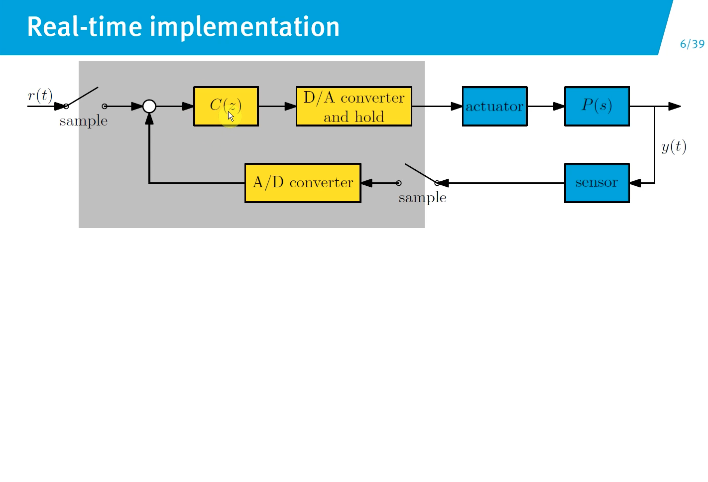

$C(s)$ is therefore not the same as $C(z)$.  This can be solved by using two solutions:
- Design it in the z-domain
- discretize the filter, this is of course dependent on the sample rate

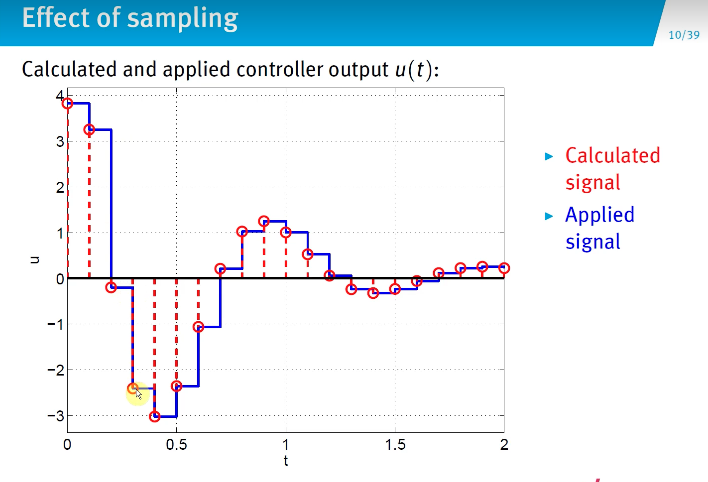

Most controllers (99%) actually hold a signal because your plant expects a real-time input. You now have a delay of $1/2T_s$ This creates a phase delay at least 90 degrees.  

## Discrete time systems

Differentiation in time domain is actually the same as difference in discrete time domain because you are just measuring the difference in time stamp k and time stamp k+1. That is why you can write this also down as:
$$
\begin{aligned}
x(k+1)&=zx(k)\\
x(k-1)&=z^{-1}x(k)\\
x(k-N)&=z^{-N}x(k)
\end{aligned}
$$ 
This means that the shift operator z is the discrete counterpart of laplace variable s:
\begin{equation}
\dot{x}(s) = sx(s) <-> x(k+1) = zx(k)
\end{equation}

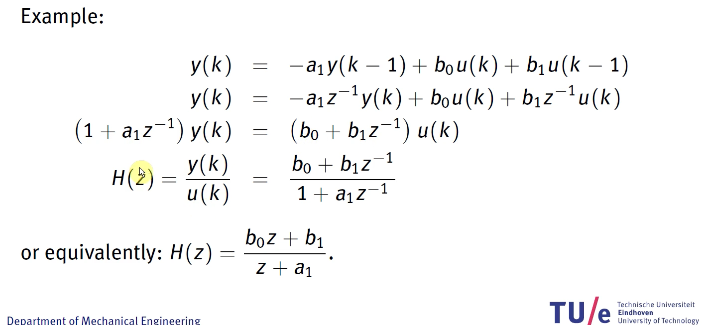

However you can also do this reversed so that:

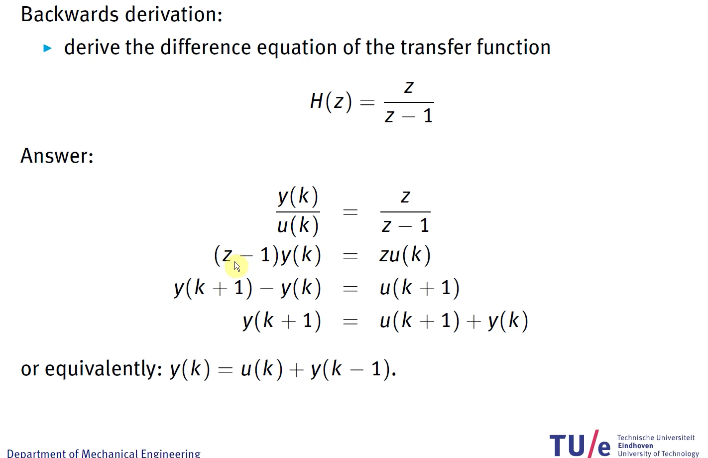

The difference equations are very easy to implement in code. 

For stability some differences occur. these are provided in the image below:
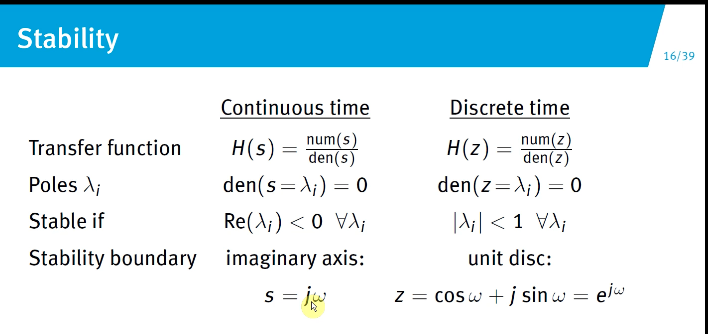

However in discrete omega is most often like the following:
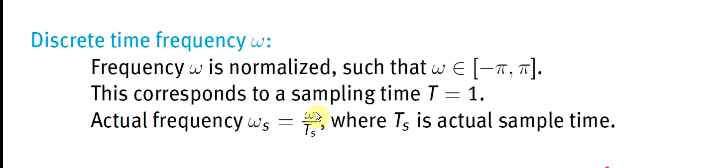

the stability is only when $|a| < 1$ because:
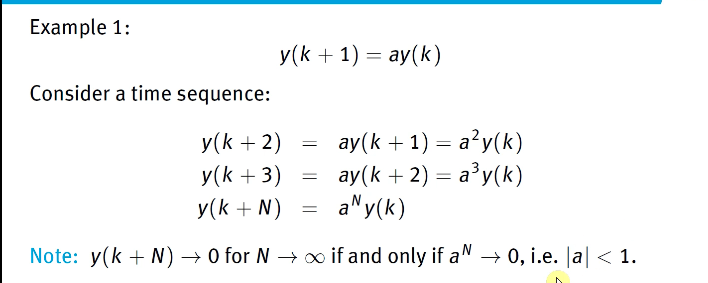

So that means poles can be on the RHP as long as they are in the unit discs. When the zeros are outside the unit discs they are minimum phase systems. 

We substitute $ze^{j\omega}$ which is the stability boundary just like in continous into $H(z)$ to obtain $H(jw)$. 


Because you are evaluating over the unit disc instead of over the imaginary axis you get taht the infromation in the bode blot is repeating itself. 
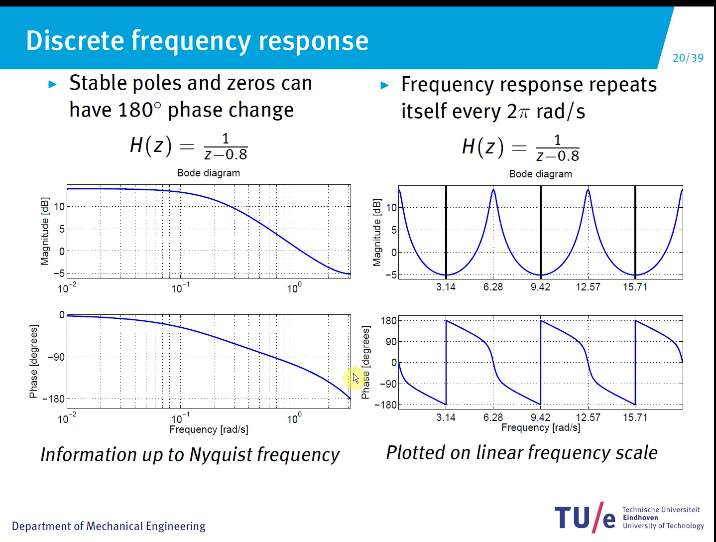

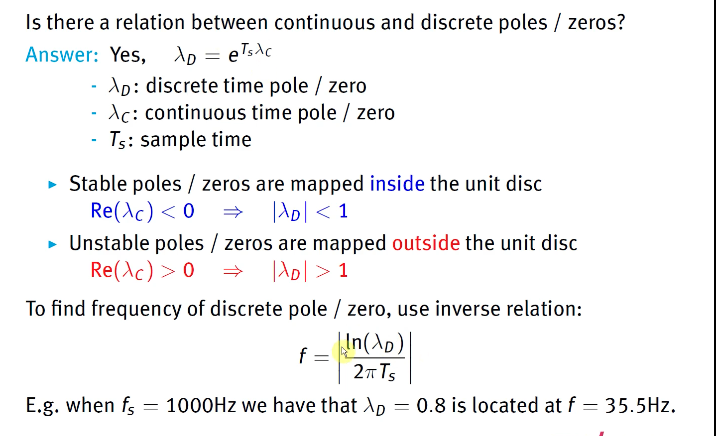

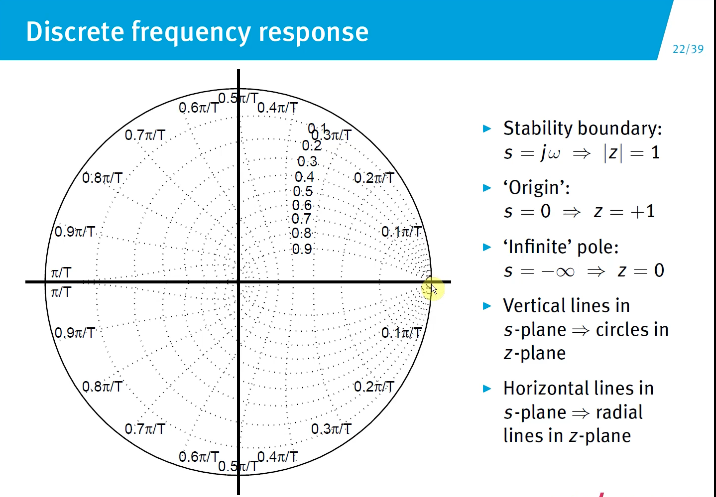

However it is easy to derive the impulse response. You just have to write it in the form:
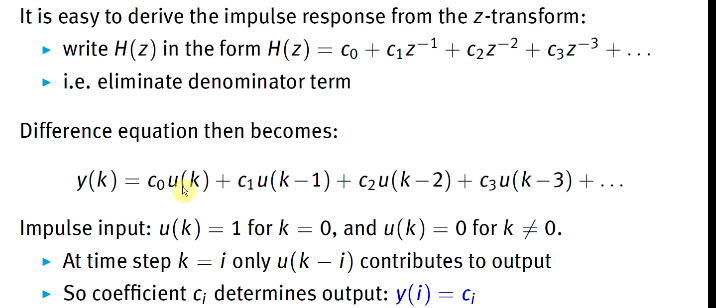

General expansion of $H(z)$ is infinite. Sometimes it is a Finite Impulse Response. This is also called a FIR. 

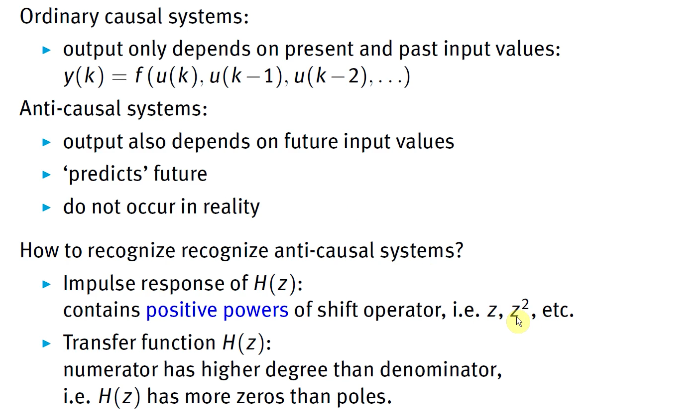

## How to convert controller from continuous to discretized time?

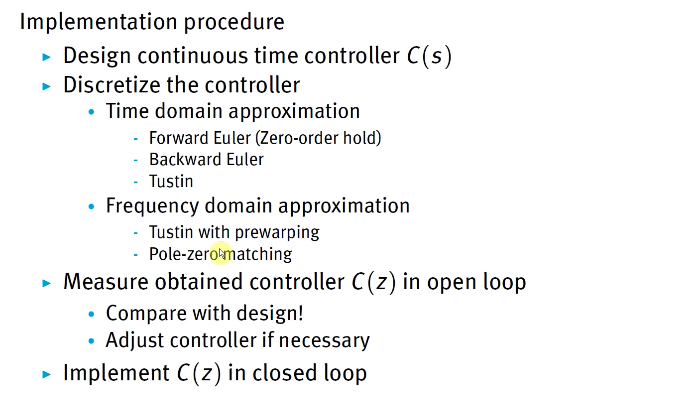

### Time domain approximations 

In this we have to make assumptions on behaviour of $u(t)$ between samples. Aka we have to assume waht the controller is doing between t(k) and t(k+1).
for eurler this is to hold so $u(t)$ is constant between samples
for Tusin, this means that there is a linear change from u(k-1) to u(k). For the upcoming explanation we are going to use continuous time integrator $C(s) = \frac{1}{s}$. To explain how to achieve this. Btw a integrator is basically trying to calculate the surface beneath the curve $u(t)$. 

For euler there are two methods one is called the forward euler. This is based on the forward difference quotient:
$$
\begin{aligned}
\dot{y}(t)&=u(t)\\
\dot{y}(t)&\approx \frac{y(t+T)-y(t)}{T} =>\frac{y(k+1)-y(k)}{T} = u(k)
\end{aligned}
$$

Shifting this in time gives:
$$
\frac{y(k)-y(k-1)}{T} = u(k)
$$
Which can be rewritten to:
$$
y(k) = y(k-1) + Tu(k-1)
$$

this gives the approximation:
$$
C(z)=\frac{Tz^{-1}}{1-z^{-1}}=\frac{T}{z-1}
$$

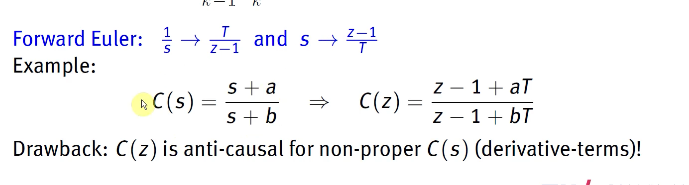

Backward euler works like this:

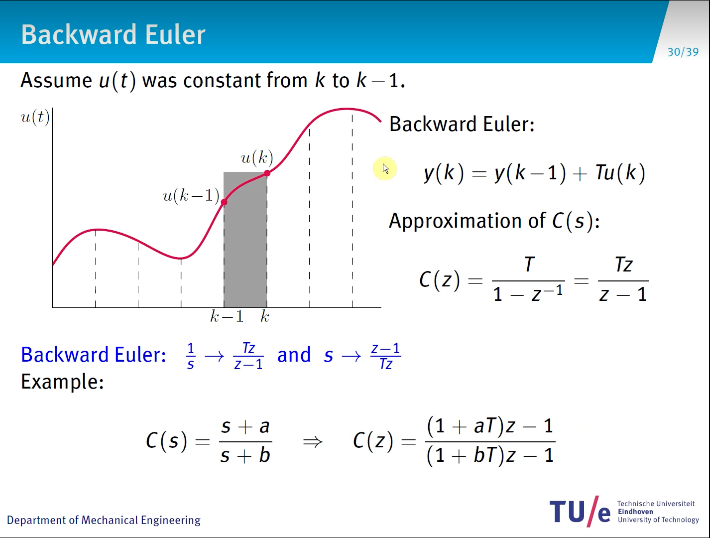

It uses the current sample to estimate the area where forward uses the previous sample. 

Tustin does the same however that takes the average value of the current input and the previous input.
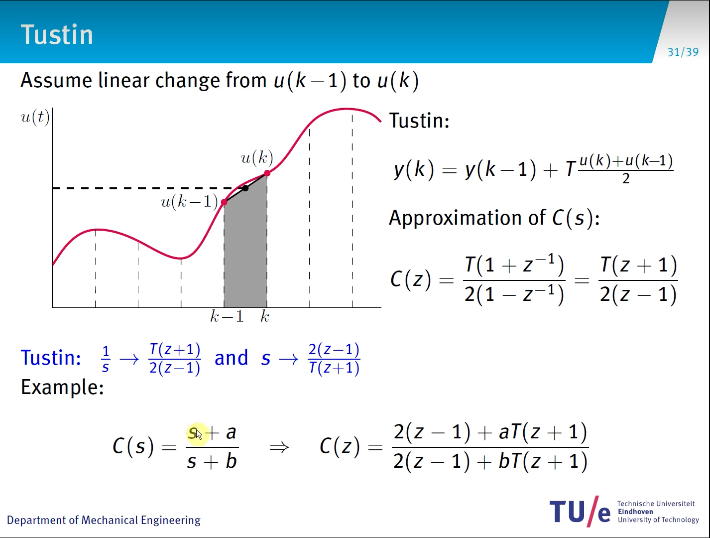

Tustin works best of these methods however they do not give a guarantee that it working well. See for example the image below.
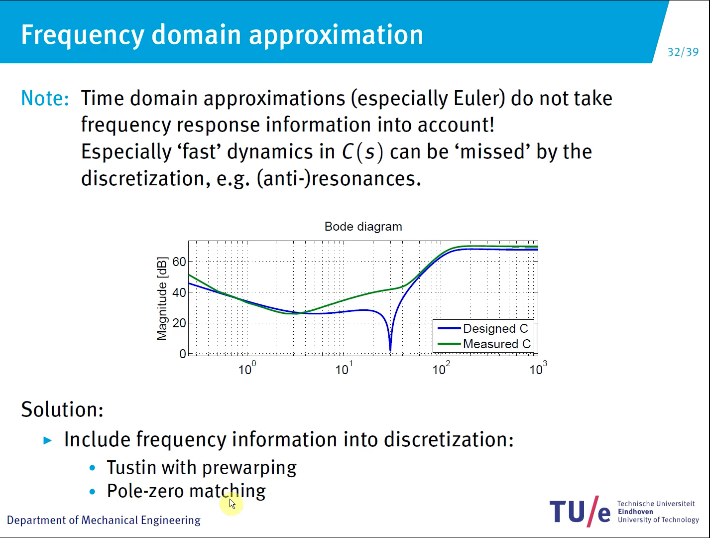

### Tustin with prewarping 
tustin with prewarping is that you match the frequency responses of $C(z)$ and $C(s)$ at a specified freq $\omega_p$. 
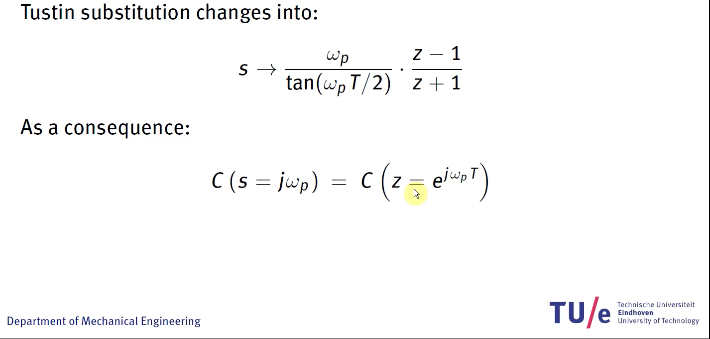

### Pole-zero matching
In here you try to map all poles and zeros to the discrete domain.
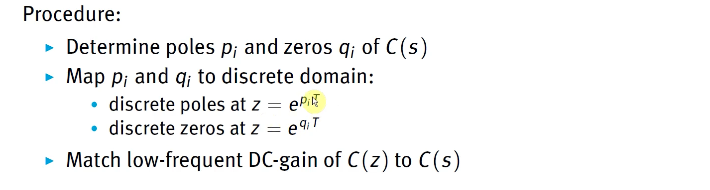
Although phase is different in discrete domain so it will never be exactly the same.
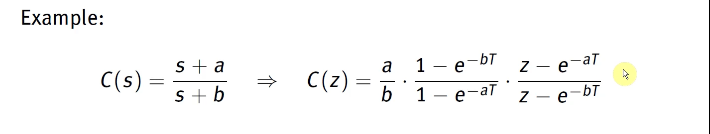

In practice tustin with prewarping is the best!

## General remarks
The smaller the sample time $T$, The better the approximation
In practice, choose sample frequency at least 20 times bandwidth
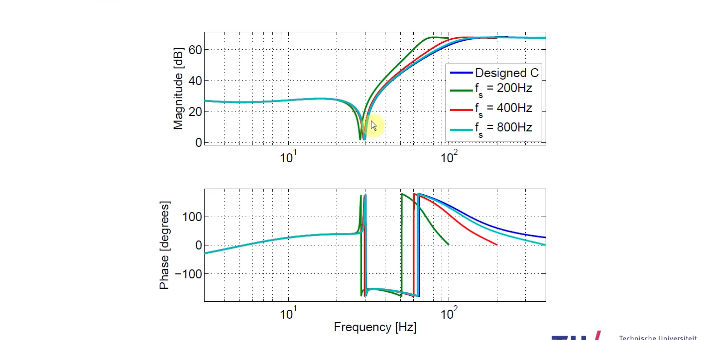
Simulink chooses its own discretization method for $C(s)$ which uses zero-order hold nearly the same as forward euler for lower T. ShapeIt comes with the DCtools blockset, this blockset uses Tusin with prewarping. The prewarping frequencies are tuned for that specific subblock. So no general prewarping frequency anymore but a decent overall. However always measure your controller after designing. 